# Assignment 2 - Learning Impairment in patients with MDD

Do patients with major depressive disorder (MDD) and healthy controls differ in how they learn from rewards? We fit a symmetric (RW) and an asymmetric (RW+/-) reinforcement-learning model to a two-armed bandit task (20 healthy, 20 depressed participants; 3 blocks of 100 trials) and compare the models and their parameters between groups.


## Imports, seed and constants

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

# setting seed for reproducibility of results
SEED = 42
np.random.seed(SEED)

N_BLOCKS = 3
TRIALS_PER_BLOCK = 100

## Processing the dataset

In [2]:
# loading dataset and dropping the first (confusing and unnamed) column
df = pd.read_csv("dataset_students.csv")
df = df.drop(df.columns[0], axis=1)

# renaming choices:
# choice: 1 = left (always the better bandit), 0 = right
df["choice"] = (df["R"] == "left").astype(int)

# block number: trials 1-100 -> 0, 101-200 -> 1, 201-300 -> 2
df["block"] = (df["trials"] - 1) // TRIALS_PER_BLOCK

# splitting on healthy and depressed participants
df_healthy = df[df["group"] == "healthy"]
df_depressed = df[df["group"] == "depressed"]

print(df.shape, "subjects:", df["subjects"].nunique())
print(df.head())
print("\nTrials per condition (healthy vs. depressed)")
print(df["group"].value_counts())
print("\nReward probabilities per block (left vs. right)")
print(df.groupby("block")[["p_left", "p_right"]].first())

(12000, 12) subjects: 40
   subjects    group  trials s_left s_right  p_left  p_right      R        rt  \
0         1  healthy       1    s_1     s_2     0.8      0.2  right  0.584142   
1         1  healthy       2    s_1     s_2     0.8      0.2  right  0.567679   
2         1  healthy       3    s_1     s_2     0.8      0.2   left  0.603843   
3         1  healthy       4    s_1     s_2     0.8      0.2  right  0.226953   
4         1  healthy       5    s_1     s_2     0.8      0.2   left  0.313892   

   reward  choice  block  
0       0       0      0  
1       0       0      0  
2       0       1      0  
3       0       0      0  
4       1       1      0  

Trials per condition (healthy vs. depressed)
group
healthy      6000
depressed    6000
Name: count, dtype: int64

Reward probabilities per block (left vs. right)
       p_left  p_right
block                 
0         0.8      0.2
1         0.7      0.3
2         0.6      0.4


## Describing the behaviour

Calculating the proportion of choosing the optimal (left) bandit

In [3]:
# adapted from the tutorial
def p_optimal(behavior):
    """Proportion of optimal choices (choice = 1 is the better bandit)"""
    return np.mean(behavior["choice"])

def p_optimal_per_block(group_df):
    """Proportion of optimal choices for every participant (rows) and block (columns)"""
    result = []
    
    for participant in group_df['subjects'].unique():
        participant_df = group_df[group_df["subjects"] == participant]
        blocks = []
        
        for block in range(N_BLOCKS):
            blocks.append(p_optimal(participant_df[participant_df["block"] == block]))

        result.append(blocks)

    return np.array(result)

healthy_p_opt = p_optimal_per_block(df_healthy)
depressed_p_opt = p_optimal_per_block(df_depressed)

print("Proportion optimal per block (healthy):  ", healthy_p_opt.mean(axis=0).round(3))
print("Proportion optimal per block (depressed):", depressed_p_opt.mean(axis=0).round(3))

Proportion optimal per block (healthy):   [0.956 0.838 0.701]
Proportion optimal per block (depressed): [0.824 0.745 0.61 ]


Plotting the results

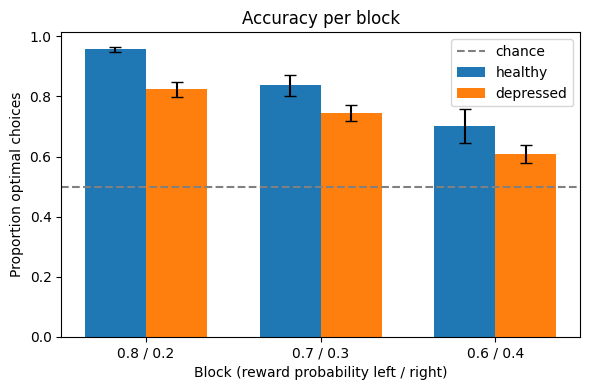

In [4]:
block_labels = ["0.8 / 0.2", "0.7 / 0.3", "0.6 / 0.4"]

# error bars = standard error of the mean
healthy_sem = scipy.stats.sem(healthy_p_opt, axis=0)
depressed_sem = scipy.stats.sem(depressed_p_opt, axis=0)

x = np.arange(N_BLOCKS)
width = 0.35
f, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - width/2, healthy_p_opt.mean(axis=0), width, yerr=healthy_sem, capsize=4, label="healthy")
ax.bar(x + width/2, depressed_p_opt.mean(axis=0), width, yerr=depressed_sem, capsize=4, label="depressed")
ax.axhline(0.5, linestyle="--", color="grey", label="chance")
ax.set_xticks(x)
ax.set_xticklabels(block_labels)
ax.set_xlabel("Block (reward probability left / right)")
ax.set_ylabel("Proportion optimal choices")
ax.set_title("Accuracy per block")
ax.legend()
plt.tight_layout()
plt.show()

## Models
We compare two models:
- **RW** (symmetric): one learning rate alpha and inverse temperature beta -> 2 parameters
- **RW+/-** (asymmetric): alpha+ for positive and alpha- for negative prediction errors, and beta -> 3 parameters

RW is RW+/- with alpha+ = alpha-, so one likelihood function covers both models.

### Softmax choice rule

In [5]:
# borrowed from the tutorial
def softmax(Q, inverse_temperature):
    """
    Computes the softmax probabilities for a given set of Q-values.

    Parameters:
        Q (ndarray): Q-values for each choice option
        inverse_temperature (float): beta parameter for softmax choice

    Returns:
        ndarray: Softmax probabilities for each choice option
    """
    z = Q*inverse_temperature
    return np.exp(z) / np.sum(np.exp(z))

### Log-likelihood of the observed choices

`ll_softmax` computes the log-likelihood for one block; `ll_all_blocks` combines the three blocks into one probability


In [6]:
# adapted from the tutorial
def ll_softmax(behavior, learning_rate_pos, learning_rate_neg, inverse_temperature, initial_q=0.5):
    """
    Computes the log-likelihood of the observed choices in one block given the model parameters.

    Parameters:
        behavior (DataFrame): choices and rewards of one block
        learning_rate_pos (float): alpha+ for positive prediction errors
        learning_rate_neg (float): alpha- for negative prediction errors
        inverse_temperature (float): beta parameter for softmax choice
        initial_q (float): initial Q-value for both options

    Returns:
        float: Summed log-likelihood of the observed choices
    """

    choices = behavior["choice"].to_numpy()
    rewards = behavior["reward"].to_numpy()

    n_trials = behavior.shape[0]
    Q = np.zeros(shape=(n_trials+1,2))+initial_q
    P = np.empty(shape=(n_trials))
    P[:] = np.nan

    for trial_n in range(n_trials):
        Q_trial = Q[trial_n, :]

        p_choices = softmax(Q_trial, inverse_temperature)

        # use the observed choice and reward instead of simulating them
        choice = choices[trial_n]
        reward = rewards[trial_n]

        # Store probability of the *observed* choice
        P[trial_n] = p_choices[choice]

        # alpha+ for positive, alpha- for negative prediction errors
        rpe = reward - Q_trial[choice]
        if rpe > 0:
            Q[trial_n + 1, choice] = Q_trial[choice] + learning_rate_pos * rpe
        else:
            Q[trial_n + 1, choice] = Q_trial[choice] + learning_rate_neg * rpe

        Q[trial_n + 1, 1 - choice] = Q_trial[1 - choice]  # carry over unchosen value

    # avoid log(0), as in the tutorial's ll_epsilon_greedy
    P[P < 1e-20] = 1e-20
    log_likelihood = np.sum(np.log(P))
    return log_likelihood

def ll_all_blocks(behavior, learning_rate_pos, learning_rate_neg, inverse_temperature):
    """Summed log-likelihood over the 3 blocks; Q-values restart at 0.5 in every block"""
    log_likelihood = 0

    for block in range(N_BLOCKS):
        block_behavior = behavior[behavior["block"] == block]
        log_likelihood += ll_softmax(block_behavior, learning_rate_pos, learning_rate_neg, inverse_temperature)
    
    return log_likelihood

### Negative log-likelihood and parameter bounds

In [7]:
# adapted from the tutorial
def neg_log_likelihood_rw(params, behavior):
    """Negative log-likelihood of RW over all blocks."""
    learning_rate = params[0]
    inverse_temperature = params[1]

    # keep parameters within bounds
    if not (0 <= learning_rate <= 1 and inverse_temperature > 0):
        return np.inf

    # symmetric model: the same learning rate for positive and negative prediction errors
    return -ll_all_blocks(behavior, learning_rate, learning_rate, inverse_temperature)

# adapted from the tutorial
def neg_log_likelihood_rw_pm(params, behavior):
    """Negative log-likelihood of RW+/- over all blocks."""
    learning_rate_pos = params[0]
    learning_rate_neg = params[1]
    inverse_temperature = params[2]
    
    # keep parameters within bounds
    if not (0 <= learning_rate_pos <= 1 and 0 <= learning_rate_neg <= 1 and inverse_temperature > 0):
        return np.inf

    # asymmetric model: (potentially) different learning rate for positive and negative prediction errors
    return -ll_all_blocks(behavior, learning_rate_pos, learning_rate_neg, inverse_temperature)

# bounds from the tutorial
bounds_rw = [(0, 1), (1e-3, 30)]
bounds_rw_pm = [(0, 1), (0, 1), (1e-3, 30)]

## Fitting both models to every participant
Each participant is fitted once on all 300 trials (Q-values restart at 0.5 in every block, see `ll_all_blocks`). This gives one set of parameters per participant. Fitting takes several minutes, so the results can be saved to `fits.csv`.

In [8]:
save_fits = False

def fit_participant(participant):
    """Fits RW and RW+/- to all trials of one participant and returns the parameters and NLLs"""

    # optimizer call borrowed from the tutorial
    result_rw = scipy.optimize.differential_evolution(neg_log_likelihood_rw, args=(participant,), bounds=bounds_rw)
    result_rw_pm = scipy.optimize.differential_evolution(neg_log_likelihood_rw_pm, args=(participant,), bounds=bounds_rw_pm)

    return {
        "subject": participant["subjects"].iloc[0],
        "group": participant["group"].iloc[0],
        "alpha": result_rw.x[0],
        "beta_rw": result_rw.x[1],
        "nll_rw": result_rw.fun,
        "alpha_pos": result_rw_pm.x[0],
        "alpha_neg": result_rw_pm.x[1],
        "beta_rw_pm": result_rw_pm.x[2],
        "nll_rw_pm": result_rw_pm.fun
    }

np.random.seed(SEED)

fits_list = []

for healthy_participant in df_healthy["subjects"].unique():
    participant_df = df_healthy[df_healthy["subjects"] == healthy_participant]
    fits_list.append(fit_participant(participant_df))
    print(f"Participant {healthy_participant} done")

for depressed_participant in df_depressed["subjects"].unique():
    participant_df = df_depressed[df_depressed["subjects"] == depressed_participant]
    fits_list.append(fit_participant(participant_df))
    print(f"Participant {depressed_participant} done")

fits = pd.DataFrame(fits_list)
if save_fits:
    fits.to_csv("fits.csv", index=False)

print(fits.round(3))

Participant 1 done
Participant 2 done
Participant 3 done
Participant 4 done
Participant 5 done
Participant 6 done
Participant 7 done
Participant 8 done
Participant 9 done
Participant 10 done
Participant 11 done
Participant 12 done
Participant 13 done
Participant 14 done
Participant 15 done
Participant 16 done
Participant 17 done
Participant 18 done
Participant 19 done
Participant 20 done
Participant 21 done
Participant 22 done
Participant 23 done
Participant 24 done
Participant 25 done
Participant 26 done
Participant 27 done
Participant 28 done
Participant 29 done
Participant 30 done
Participant 31 done
Participant 32 done
Participant 33 done
Participant 34 done
Participant 35 done
Participant 36 done
Participant 37 done
Participant 38 done
Participant 39 done
Participant 40 done
    subject      group  alpha  beta_rw   nll_rw  alpha_pos  alpha_neg  \
0         1    healthy  0.180    4.859   92.600      0.274      0.051   
1         2    healthy  0.165    7.694  109.870      0.193     

In [ ]:
# optional: skip the fitting cell above to load an already fitted csv from previous run
fits = pd.read_csv("fits.csv")

## Model comparison (BIC)

BIC = 2 · NLL + k · ln(n), with k = number of free parameters (RW: 2, RW+/-: 3) and n = number of trials (300). Lower BIC is better: the extra parameter of RW+/- is only worth it if it improves the fit by more than the penalty ln(300) ≈ 5.7.

In [10]:
n_trials = N_BLOCKS * TRIALS_PER_BLOCK

# BIC formula borrowed from the tutorial
fits["bic_rw"] = 2 * fits["nll_rw"] + 2 * np.log(n_trials)
fits["bic_rw_pm"] = 2 * fits["nll_rw_pm"] + 3 * np.log(n_trials)

# True if RW+/- has the lower (better) BIC for this participant
fits["rw_pm_better"] = fits["bic_rw_pm"] < fits["bic_rw"]

print("Number of participants best fit by RW+/- (out of 20)")
print(fits.groupby("group")["rw_pm_better"].sum())
print("\nSummed BIC per group (lower is better)")
print(fits.groupby("group")[["bic_rw", "bic_rw_pm"]].sum().round(1))

Number of participants best fit by RW+/- (out of 20)
group
depressed     3
healthy      15
Name: rw_pm_better, dtype: int64

Summed BIC per group (lower is better)
           bic_rw  bic_rw_pm
group                       
depressed  5801.4     5848.9
healthy    3852.0     3390.5


Plotting BIC  results

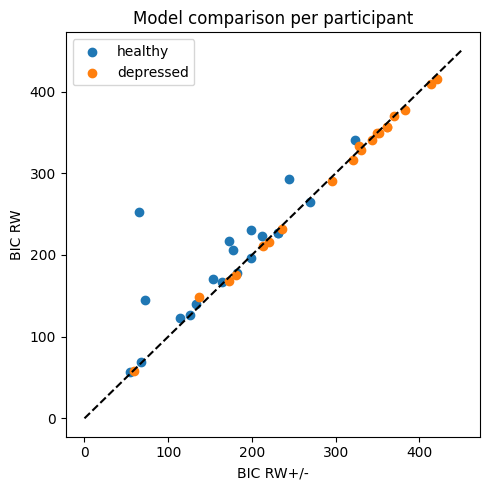

In [11]:
# BIC of RW vs. RW+/- per participant
f, ax = plt.subplots(figsize=(5, 5))
for group in ["healthy", "depressed"]:
    group_fits = fits[fits["group"] == group]
    ax.scatter(group_fits["bic_rw_pm"], group_fits["bic_rw"], label=group)

# diagonal: both models equally good; points above it are better fit by RW+/-
ax.plot([0, 450], [0, 450], "k--")
ax.set_xlabel("BIC RW+/-")
ax.set_ylabel("BIC RW")
ax.set_title("Model comparison per participant")
ax.legend()
plt.tight_layout()
plt.show()


## Comparing parameters between groups

For each fitted parameter we compare healthy vs. depressed participants with an independent-samples t-test

In [12]:
healthy_fits = fits[fits["group"] == "healthy"]
depressed_fits = fits[fits["group"] == "depressed"]

for column in ["alpha", "beta_rw", "alpha_pos", "alpha_neg", "beta_rw_pm"]:
    result = scipy.stats.ttest_ind(healthy_fits[column], depressed_fits[column])
    print(column)
    print(f"  healthy:   mean = {healthy_fits[column].mean():.3f}, sd = {healthy_fits[column].std():.3f}")
    print(f"  depressed: mean = {depressed_fits[column].mean():.3f}, sd = {depressed_fits[column].std():.3f}")
    print(f"  t = {result.statistic:.2f}, p = {result.pvalue:.3f}")

alpha
  healthy:   mean = 0.113, sd = 0.073
  depressed: mean = 0.197, sd = 0.133
  t = -2.49, p = 0.017
beta_rw
  healthy:   mean = 14.476, sd = 9.758
  depressed: mean = 5.993, sd = 5.683
  t = 3.36, p = 0.002
alpha_pos
  healthy:   mean = 0.249, sd = 0.131
  depressed: mean = 0.204, sd = 0.178
  t = 0.90, p = 0.374
alpha_neg
  healthy:   mean = 0.072, sd = 0.041
  depressed: mean = 0.210, sd = 0.192
  t = -3.16, p = 0.003
beta_rw_pm
  healthy:   mean = 10.278, sd = 6.046
  depressed: mean = 6.207, sd = 3.751
  t = 2.56, p = 0.015


Plotting participant parameters

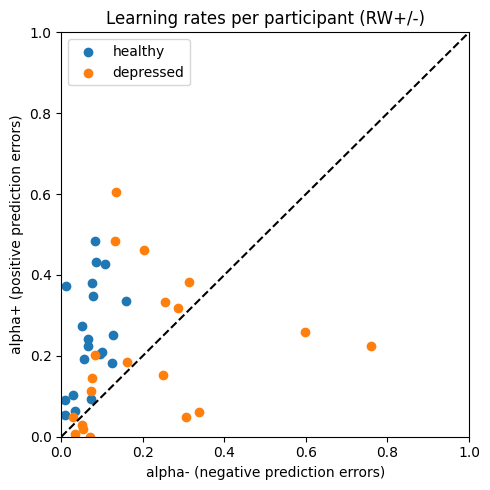

In [13]:
f, ax = plt.subplots(figsize=(5, 5))

for group in ["healthy", "depressed"]:
    group_fits = fits[fits["group"] == group]
    ax.scatter(group_fits["alpha_neg"], group_fits["alpha_pos"], label=group)
ax.plot([0, 1], [0, 1], "k--")  # diagonal: alpha+ = alpha- (no learning bias)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("alpha- (negative prediction errors)")
ax.set_ylabel("alpha+ (positive prediction errors)")
ax.set_title("Learning rates per participant (RW+/-)")
ax.legend()

plt.tight_layout()
plt.show()

## Parameter recovery (RW+/-)

Simulating participants with known parameters in the same task (3 blocks of 100 trials with reward probabilities 0.8/0.2, 0.7/0.3, 0.6/0.4), fitting RW+/- to the simulated data, and checking whether the recovered parameters match the true ones.

In [14]:
# adapted from the tutorial
def simulate_rw_pm(learning_rate_pos, learning_rate_neg, inverse_temperature, p_reward_blocks, initial_Q=0.5):
    """Simulates one participant with RW+/- in a multi-block bandit task; Q-values restart in every block
    
    Parameters:
        learning_rate_pos (float): alpha+ for positive prediction errors
        learning_rate_neg (float): alpha- for negative prediction errors
        inverse_temperature (float): beta parameter for softmax choice
        p_reward_blocks (list): reward probabilities [option 0, option 1] for each block
        initial_Q (float): initial Q-value for both options

    Returns:
        DataFrame: choice, reward and block for every trial
    """
    all_blocks = []

    for block, p_reward in enumerate(p_reward_blocks):
        Q = np.zeros(shape=(TRIALS_PER_BLOCK + 1, 2)) + initial_Q
        behavior = pd.DataFrame(index=np.arange(TRIALS_PER_BLOCK), columns=["choice", "reward"])

        for trial_n in range(TRIALS_PER_BLOCK):
            Q_trial = Q[trial_n, :]

            # Sample a choice and a reward
            p_choices = softmax(Q_trial, inverse_temperature)
            choice_idx = np.random.choice([0, 1], p=p_choices)
            reward = np.random.binomial(n=1, p=p_reward[choice_idx])

            # Record choice and reward
            behavior.loc[trial_n, "choice"] = choice_idx
            behavior.loc[trial_n, "reward"] = reward

            # Update Q-value of the chosen option with alpha+ or alpha-
            rpe = reward - Q_trial[choice_idx]
            if rpe > 0:
                Q[trial_n + 1, choice_idx] = Q_trial[choice_idx] + learning_rate_pos * rpe
            else:
                Q[trial_n + 1, choice_idx] = Q_trial[choice_idx] + learning_rate_neg * rpe

            # Carry forward unchosen Q-value
            Q[trial_n + 1, 1 - choice_idx] = Q_trial[1 - choice_idx]

        behavior["block"] = block
        all_blocks.append(behavior)

    return pd.concat(all_blocks, ignore_index=True).astype(int)


# reward probabilities per block: option 1 (left) is the better bandit, as in the data
P_REWARD_BLOCKS = [[0.2, 0.8], [0.3, 0.7], [0.4, 0.6]]

# parameter recovery procedure borrowed from the tutorial
np.random.seed(SEED)
n_sets = 20

# true parameters, sampled within the range of the fitted values
true_lr_pos = np.random.uniform(0, 0.8, n_sets)
true_lr_neg = np.random.uniform(0, 0.8, n_sets)
true_beta = np.random.uniform(1, 20, n_sets)

recovered = np.zeros(shape=(n_sets, 3))

for set_n in range(n_sets):
    # 1. Simulate a dataset with known parameters
    behavior = simulate_rw_pm(true_lr_pos[set_n], true_lr_neg[set_n], true_beta[set_n], P_REWARD_BLOCKS)

    # 2. Fit RW+/- to the simulated data
    result = scipy.optimize.differential_evolution(neg_log_likelihood_rw_pm, args=(behavior,), bounds=bounds_rw_pm)

    # 3. Save the estimated parameters
    recovered[set_n] = result.x
    print(f"Set {set_n+1} done")

Set 1 done
Set 2 done
Set 3 done
Set 4 done
Set 5 done
Set 6 done
Set 7 done
Set 8 done
Set 9 done
Set 10 done
Set 11 done
Set 12 done
Set 13 done
Set 14 done
Set 15 done
Set 16 done
Set 17 done
Set 18 done
Set 19 done
Set 20 done


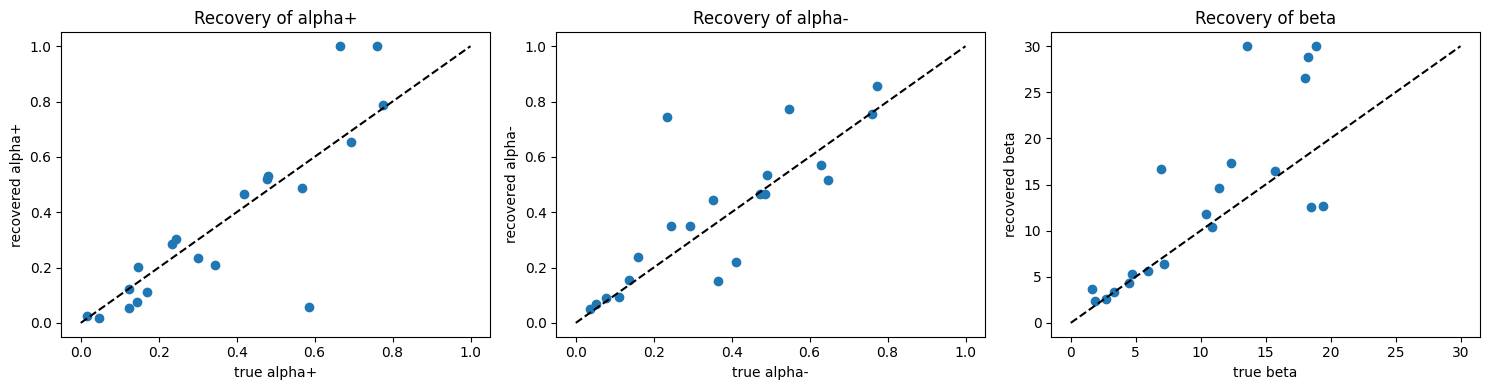

In [15]:
# true vs. recovered parameters
true_values = [true_lr_pos, true_lr_neg, true_beta]
labels = ["alpha+", "alpha-", "beta"]
upper_limits = [1, 1, 30]

f, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in range(3):
    ax[i].plot(true_values[i], recovered[:, i], "o")
    ax[i].plot([0, upper_limits[i]], [0, upper_limits[i]], "k--")
    ax[i].set_xlabel(f"true {labels[i]}")
    ax[i].set_ylabel(f"recovered {labels[i]}")
    ax[i].set_title(f"Recovery of {labels[i]}")
plt.tight_layout()
plt.show()